In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('database.csv')

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2795 entries, 0 to 2794
Data columns (total 48 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Report Number                         2795 non-null   int64  
 1   Supplemental Number                   2795 non-null   int64  
 2   Accident Year                         2795 non-null   int64  
 3   Accident Date/Time                    2795 non-null   str    
 4   Operator ID                           2795 non-null   int64  
 5   Operator Name                         2795 non-null   str    
 6   Pipeline/Facility Name                2674 non-null   str    
 7   Pipeline Location                     2795 non-null   str    
 8   Pipeline Type                         2777 non-null   str    
 9   Liquid Type                           2795 non-null   str    
 10  Liquid Subtype                        1349 non-null   str    
 11  Liquid Name                 

In [19]:
df.shape

(2795, 48)

In [20]:
cause_columns = [
    'Pipeline Location',
    'Pipeline Type',
    'Liquid Type',
    'Liquid Subtype',
    'Cause Category',
    'Cause Subcategory',
    'Liquid Ignition',
    'Liquid Explosion',
    'Pipeline Shutdown',
    'Unintentional Release (Barrels)',
    'Intentional Release (Barrels)',
    'Liquid Recovery (Barrels)',
    'Net Loss (Barrels)',
    'Public Evacuations',
    'Operator Employee Injuries',
    'Operator Contractor Injuries',
    'Emergency Responder Injuries',
    'Other Injuries',
    'Public Injuries',
    'All Injuries',
    'Operator Employee Fatalities',
    'Operator Contractor Fatalities',
    'Emergency Responder Fatalities',
    'Other Fatalities',
    'Public Fatalities',
    'All Fatalities',
    'Property Damage Costs',
    'Lost Commodity Costs',
    'Public/Private Property Damage Costs',
    'Emergency Response Costs',
    'Environmental Remediation Costs',
    'Other Costs',
    'All Costs'
]

new_df = df[cause_columns].copy()
new_df.head()

,Pipeline Location,Pipeline Type,Liquid Type,Liquid Subtype,Cause Category,Cause Subcategory,Liquid Ignition,Liquid Explosion,Pipeline Shutdown,Unintentional Release (Barrels),...,Other Fatalities,Public Fatalities,All Fatalities,Property Damage Costs,Lost Commodity Costs,Public/Private Property Damage Costs,Emergency Response Costs,Environmental Remediation Costs,Other Costs,All Costs
0,ONSHORE,ABOVEGROUND,"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",LPG (LIQUEFIED PETROLEUM GAS) / NGL (NATURAL G...,INCORRECT OPERATION,PIPELINE/EQUIPMENT OVERPRESSURED,NO,NO,NO,21.00,...,NaN,NaN,NaN,110.0,1517.0,0.0,0.0,0.0,0.0,1627
1,ONSHORE,ABOVEGROUND,CRUDE OIL,NaN,MATERIAL/WELD/EQUIP FAILURE,PUMP OR PUMP-RELATED EQUIPMENT,NO,NO,NaN,0.12,...,NaN,NaN,NaN,4000.0,8.0,0.0,0.0,0.0,0.0,4008
2,ONSHORE,ABOVEGROUND,"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",OTHER HVL,MATERIAL/WELD/EQUIP FAILURE,DEFECTIVE OR LOOSE TUBING/FITTING,NO,NO,NaN,2.00,...,NaN,NaN,NaN,0.0,200.0,0.0,0.0,0.0,0.0,200
3,ONSHORE,UNDERGROUND,CRUDE OIL,NaN,NATURAL FORCE DAMAGE,TEMPERATURE,NO,NO,NaN,0.48,...,NaN,NaN,NaN,200.0,40.0,0.0,11300.0,0.0,0.0,11540
4,ONSHORE,UNDERGROUND,CRUDE OIL,NaN,EXCAVATION DAMAGE,THIRD PARTY EXCAVATION DAMAGE,NO,NO,NO,700.00,...,NaN,NaN,NaN,20000.0,150.0,0.0,7500.0,2000.0,0.0,29650


In [21]:
# Keep features with fewer than 1,000 missing values.
null_counts = new_df.isnull().sum()
new_df = new_df[null_counts[null_counts < 1000].index]
new_df.shape

(2795, 19)

In [22]:
new_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2795 entries, 0 to 2794
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Pipeline Location                     2795 non-null   str    
 1   Pipeline Type                         2777 non-null   str    
 2   Liquid Type                           2795 non-null   str    
 3   Cause Category                        2795 non-null   str    
 4   Cause Subcategory                     2795 non-null   str    
 5   Liquid Ignition                       2795 non-null   str    
 6   Liquid Explosion                      2795 non-null   str    
 7   Pipeline Shutdown                     2583 non-null   str    
 8   Unintentional Release (Barrels)       2795 non-null   float64
 9   Liquid Recovery (Barrels)             2795 non-null   float64
 10  Net Loss (Barrels)                    2795 non-null   float64
 11  Public Evacuations          

Most frequent value for each feature:


,feature,most_frequent_value,frequency,frequency_percent
0,Liquid Explosion,NO,2780,99.46
1,Pipeline Location,ONSHORE,2777,99.36
2,Liquid Ignition,NO,2700,96.60
3,Public/Private Property Damage Costs,0.0,2527,90.74
4,Other Costs,0.0,2465,88.70
5,Public Evacuations,0.0,2285,97.73
6,Net Loss (Barrels),0.0,1489,53.27
7,Pipeline Type,ABOVEGROUND,1475,53.11
8,Cause Category,MATERIAL/WELD/EQUIP FAILURE,1435,51.34
9,Liquid Type,CRUDE OIL,1398,50.02


Exported to most_frequent_by_feature.csv


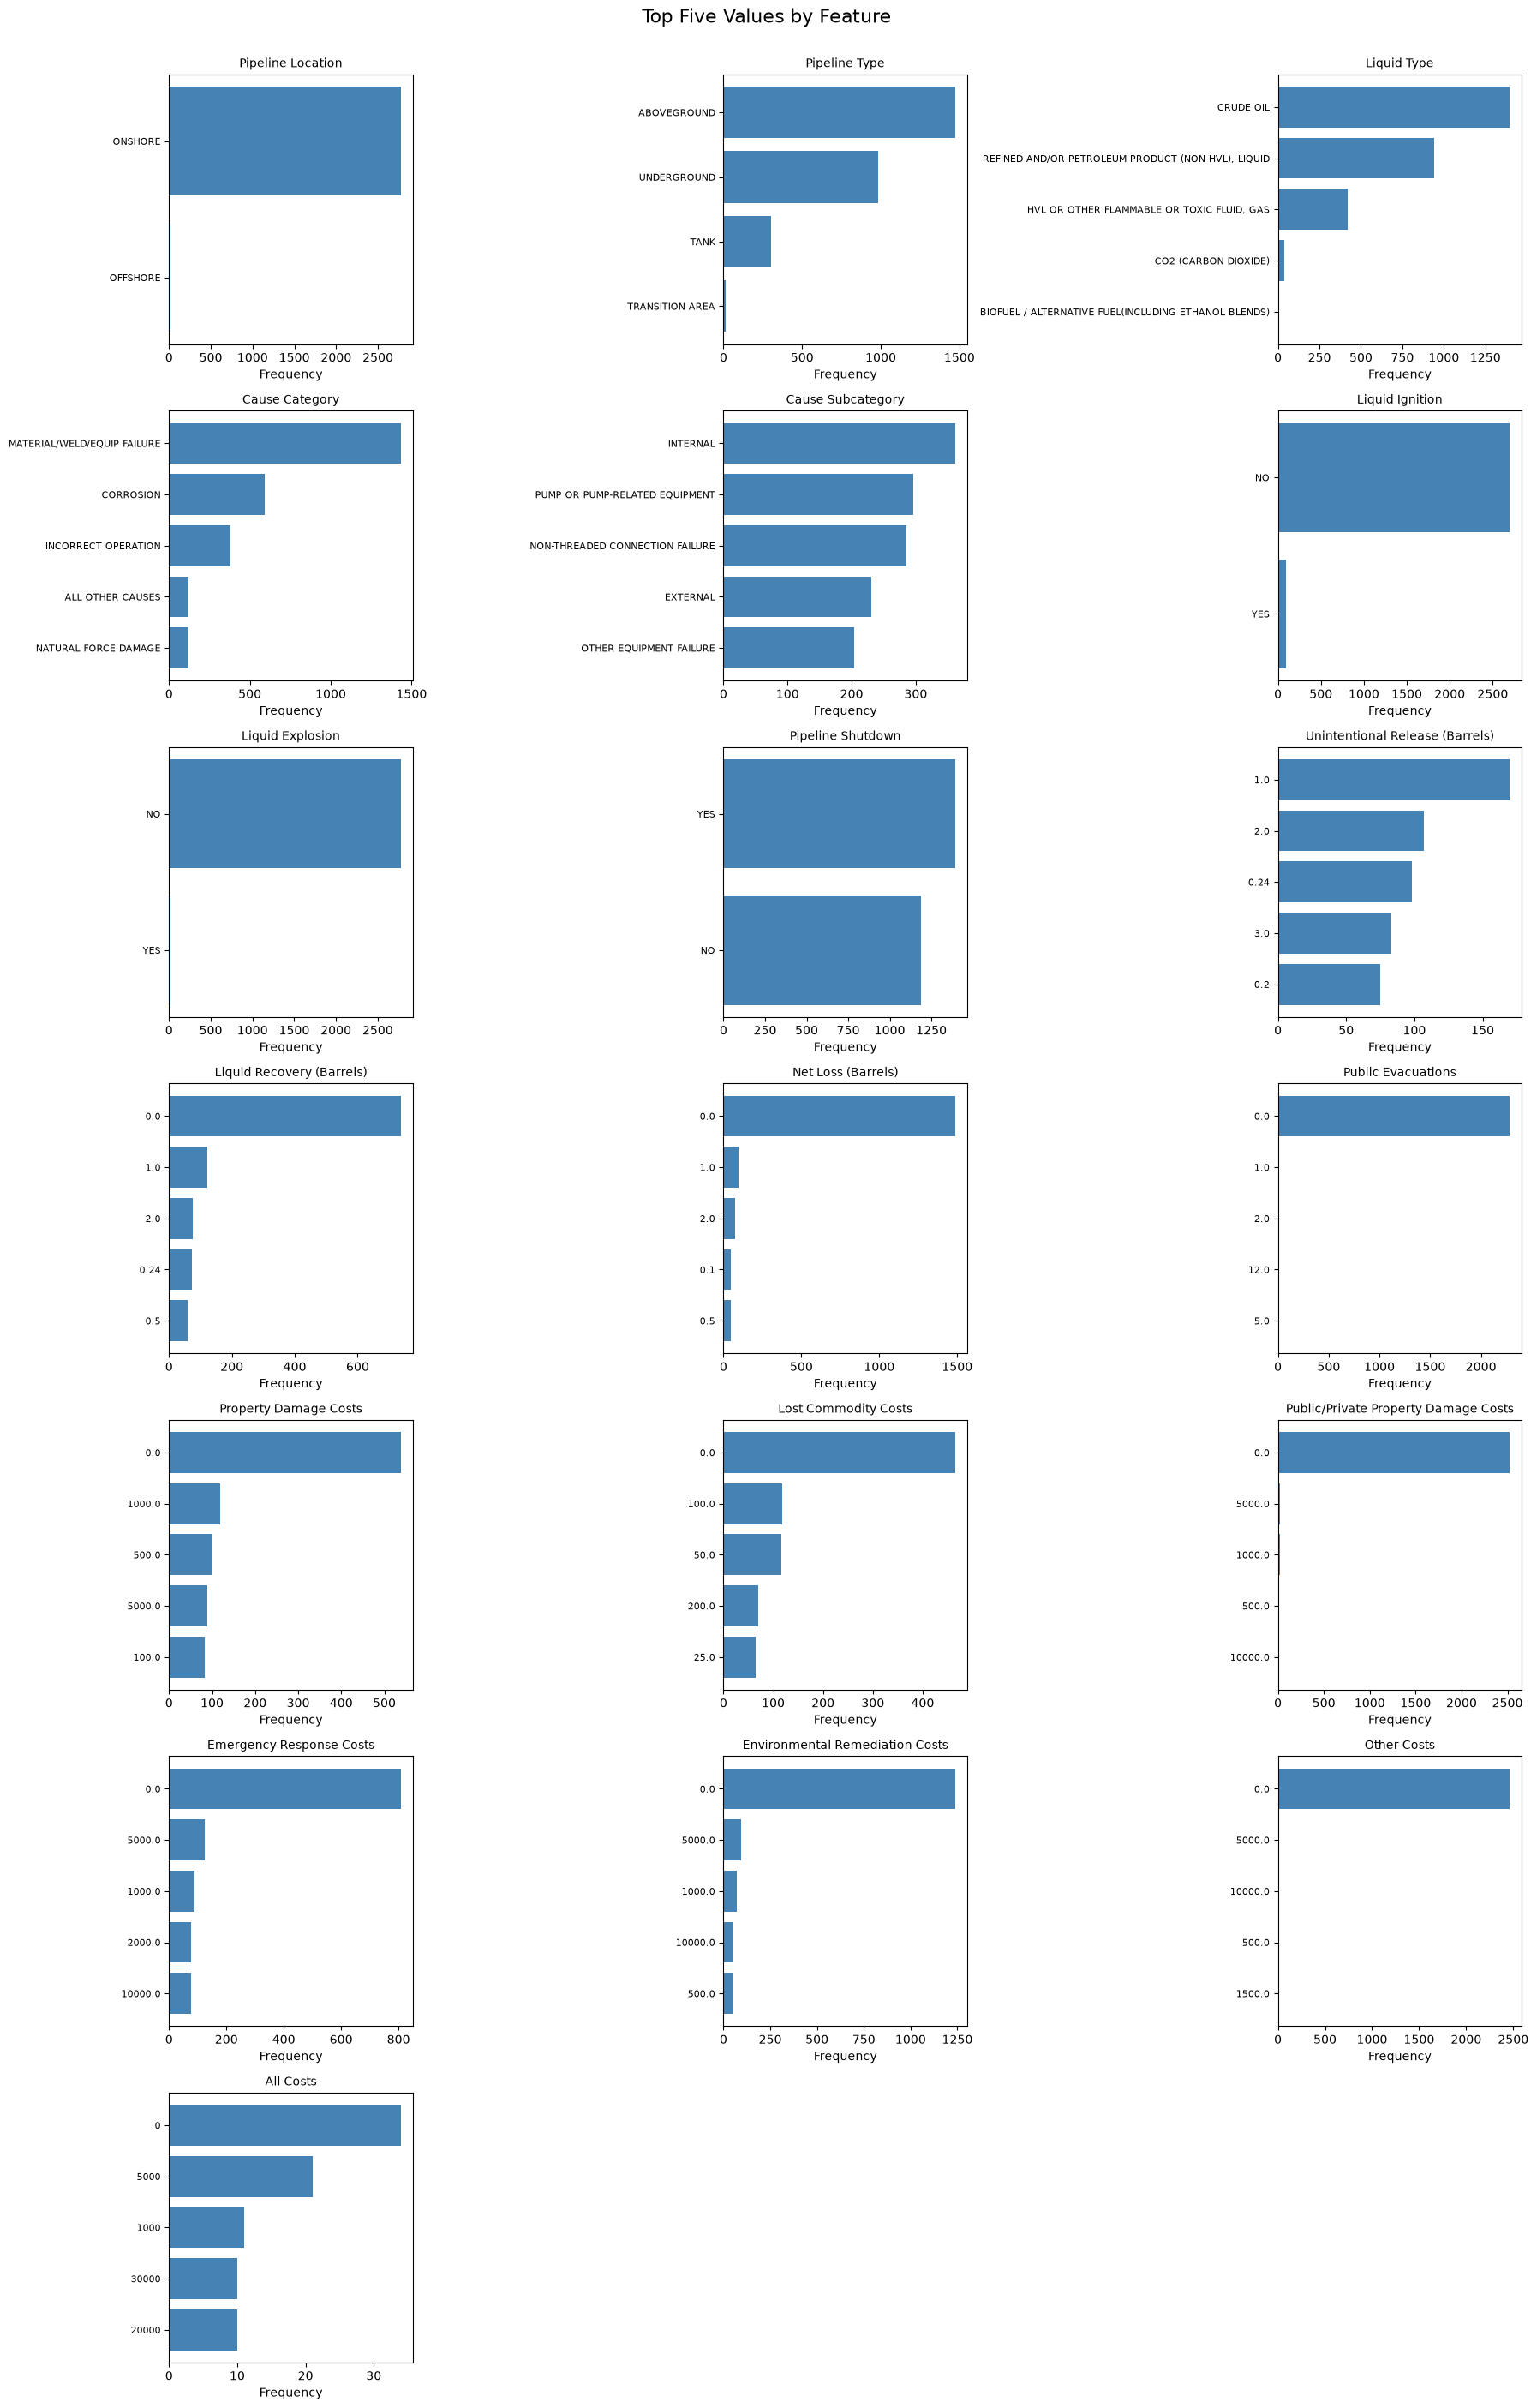

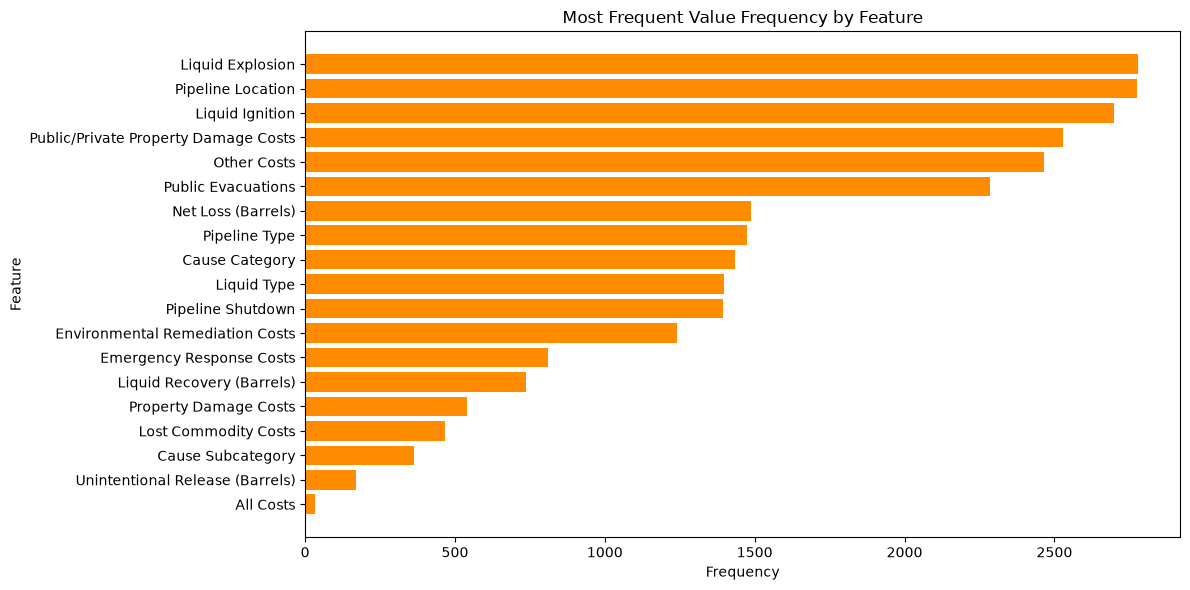

In [23]:
most_frequent_rows = []

for feature in new_df.columns:
    value_counts = new_df[feature].dropna().value_counts()

    if not value_counts.empty:
        most_frequent_rows.append({
            'feature': feature,
            'most_frequent_value': value_counts.index[0],
            'frequency': int(value_counts.iloc[0]),
            'frequency_percent': round(value_counts.iloc[0] / value_counts.sum() * 100, 2)
        })

most_frequent_df = pd.DataFrame(most_frequent_rows)
most_frequent_df = most_frequent_df.sort_values('frequency', ascending=False).reset_index(drop=True)
most_frequent_df.to_csv('most_frequent_by_feature.csv', index=False)

print('Most frequent value for each feature:')
display(most_frequent_df)
print('Exported to most_frequent_by_feature.csv')

# Compare the five most frequent values for each feature.
feature_names = new_df.columns
number_of_columns = 3
number_of_rows = int(np.ceil(len(feature_names) / number_of_columns))
fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(18, number_of_rows * 4),
    squeeze=False
)
axes = axes.ravel()

for axis, feature in zip(axes, feature_names):
    top_values = new_df[feature].dropna().value_counts().head(5).sort_values()
    axis.barh(top_values.index.astype(str), top_values.values, color='steelblue')
    axis.set_title(feature, fontsize=10)
    axis.set_xlabel('Frequency')
    axis.tick_params(axis='y', labelsize=8)

for axis in axes[len(feature_names):]:
    axis.set_visible(False)

fig.suptitle('Top Five Values by Feature', fontsize=16, y=1.002)
plt.tight_layout()
fig.savefig('top_five_values_by_feature.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualize the modal frequency across all features.
frequency_fig = plt.figure(figsize=(12, max(6, len(most_frequent_df) * 0.3)))
plt.barh(
    most_frequent_df['feature'],
    most_frequent_df['frequency'],
    color='darkorange'
)
plt.xlabel('Frequency')
plt.ylabel('Feature')
plt.title('Most Frequent Value Frequency by Feature')
plt.gca().invert_yaxis()
plt.tight_layout()
frequency_fig.savefig('most_frequent_frequency_by_feature.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
from sklearn.preprocessing import OrdinalEncoder

# Fill missing values so clustering receives a complete numeric matrix.
model_df = new_df.copy()
for column in model_df.columns:
    if pd.api.types.is_numeric_dtype(model_df[column]):
        model_df[column] = model_df[column].fillna(model_df[column].median())
    else:
        model_df[column] = model_df[column].fillna('UNKNOWN')

X = np.zeros((len(model_df), len(model_df.columns)), dtype=float)
encoders = []
right_indices = []

for column_index, column in enumerate(model_df.columns):
    if pd.api.types.is_numeric_dtype(model_df[column]):
        X[:, column_index] = model_df[column].to_numpy(dtype=float)
    else:
        encoder = OrdinalEncoder()
        X[:, column_index] = encoder.fit_transform(model_df[[column]]).ravel()
        encoders.append(encoder)
        right_indices.append(column_index)

X

array([[1.0000e+00, 0.0000e+00, 3.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        1.6270e+03],
       [1.0000e+00, 0.0000e+00, 2.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        4.0080e+03],
       [1.0000e+00, 0.0000e+00, 3.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        2.0000e+02],
       ...,
       [1.0000e+00, 1.0000e+00, 2.0000e+00, ..., 3.0000e+03, 0.0000e+00,
        1.5050e+04],
       [1.0000e+00, 3.0000e+00, 4.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        4.1428e+04],
       [1.0000e+00, 0.0000e+00, 2.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        4.5800e+04]], shape=(2795, 19))

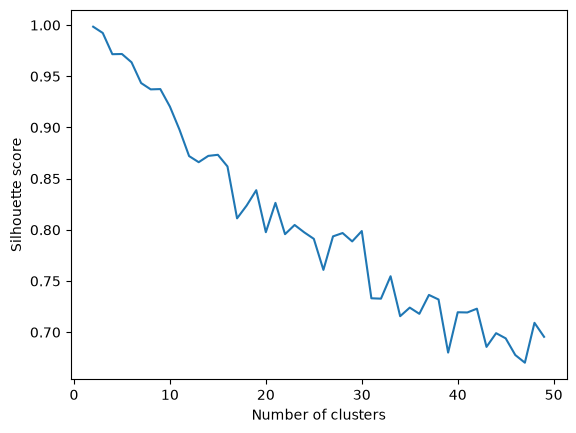

2


In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
scores = []
for i in range(2, 50):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    cluster_labels = model.fit_predict(X)
    scores.append(silhouette_score(X, cluster_labels))
plt.plot(range(2, 50), scores)
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.show()
print(np.argmax(scores) + 2)

In [28]:
model = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = model.fit_predict(X)
centers = model.cluster_centers_

# Decode ordinal categorical features into their original labels.
decoded_centers = centers.astype(object)
for encoder, column_index in zip(encoders, right_indices):
    encoded_values = np.rint(centers[:, column_index]).astype(int)
    encoded_values = np.clip(encoded_values, 0, len(encoder.categories_[0]) - 1)
    decoded_centers[:, column_index] = encoder.inverse_transform(
        encoded_values.reshape(-1, 1)
    ).ravel()

cluster_centers_df = pd.DataFrame(decoded_centers, columns=model_df.columns)

# Round numeric center values to the nearest whole number.
for column in cluster_centers_df.columns:
    numeric_values = pd.to_numeric(cluster_centers_df[column], errors='coerce')
    numeric_mask = numeric_values.notna()
    cluster_centers_df.loc[numeric_mask, column] = numeric_values[numeric_mask].round().astype(int)

cluster_centers_df.index.name = 'cluster'
cluster_centers_df

,Pipeline Location,Pipeline Type,Liquid Type,Cause Category,Cause Subcategory,Liquid Ignition,Liquid Explosion,Pipeline Shutdown,Unintentional Release (Barrels),Liquid Recovery (Barrels),Net Loss (Barrels),Public Evacuations,Property Damage Costs,Lost Commodity Costs,Public/Private Property Damage Costs,Emergency Response Costs,Environmental Remediation Costs,Other Costs,All Costs
cluster,,,,,,,,,,,,,,,,,,,
0,ONSHORE,TANK,"HVL OR OTHER FLAMMABLE OR TOXIC FLUID, GAS",INCORRECT OPERATION,MARITIME EQUIPMENT OR VESSEL ADRIFT,NO,NO,UNKNOWN,200,69,132,1,110989,9750,16809,228024,134630,33313,533499
1,ONSHORE,UNDERGROUND,CRUDE OIL,MATERIAL/WELD/EQUIP FAILURE,ENVIRONMENTAL CRACKING-RELATED,NO,NO,YES,20082,18245,1837,61,3000000,126118,23000000,177000000,635000000,2400000,840526118


In [29]:
cluster_centers_df.to_csv('centers_of_incidents.csv', index=False)